# Fundamentals of Data Science – Case Studies 3 & 6 (Batch 3)
**Case Study 3:** Titanic Survival Prediction using Logistic Regression  
**Case Study 6:** Bank Marketing – Term Deposit Prediction (4 datasets, 4 models)

| Field | Details |
|---|---|
| Name | P. Mahesh Nayak |
| Roll No | 160124733193 |
| Section / Year | CSE-3 / Third Year |
| Subject | Fundamentals of Data Science |
| Faculty | S. Durga Devi |
| Institute | Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad |

**Files to upload to Colab sidebar:**
- `titanic_1.csv` (for CS3)
- `bank.csv`, `bank-additional.csv`, `bank-full.csv`, `bank-additional-full.csv` (for CS6)

Upload them all at once, then run the cells below.

In [5]:
# Setup: import libraries and configure paths
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
# --- FIX: Split the standard scaler and simple imputer into their correct modules ---
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
# ------------------------------------------------------------------------------------
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.preprocessing import OneHotEncoder

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
os.makedirs("Images", exist_ok=True)
os.makedirs("Data", exist_ok=True)
print("Libraries loaded successfully.")


Libraries loaded successfully.


---
# PART A — Case Study 3: Titanic Survival Prediction (Logistic Regression)

## A1. Problem Statement
The sinking of the RMS Titanic in 1912 killed most of its passengers. The aim is to build a **binary classification model** that predicts whether a passenger survived (`Survived` = 1) or not (0) from attributes such as class, sex, age, family size, fare and port of embarkation, and to **interpret** which factors influenced survival.

## A2. Methodology
1. Load the data and inspect structure, missing values and summary statistics
2. Exploratory data analysis (EDA) with interpreted graphs
3. Preprocessing: missing-value imputation, feature engineering, one-hot encoding, scaling
4. Train/test split (80:20, stratified) and Logistic Regression
5. Evaluation: accuracy, precision, recall, F1, confusion matrix, ROC-AUC, cross-validation
6. Interpretation of coefficients (odds ratios)
7. Save the model

In [6]:
# A3. Load Titanic dataset
titanic = pd.read_csv("titanic.csv")
titanic.to_csv("Data/titanic_used.csv", index=False)
print("Shape:", titanic.shape)
print("\nFirst 5 rows:"); titanic.head()

Shape: (891, 12)

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
# Structure, data types, missing values and summary statistics
titanic.info()
print("\nMissing values per column:\n", titanic.isnull().sum())
print("\nSummary statistics:"); titanic.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values per column:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embark

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


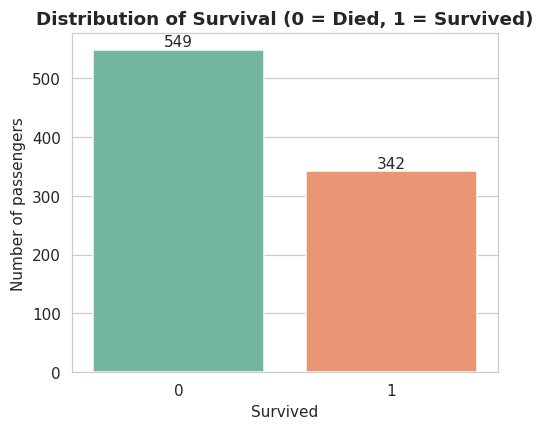

Interpretation: 38.4% of passengers survived. Classes are imbalanced toward 'died'.


In [8]:
# A4. EDA – survival distribution
plt.figure(figsize=(5,4))
ax = sns.countplot(x="Survived", data=titanic, palette="Set2")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Distribution of Survival (0 = Died, 1 = Survived)", fontsize=12, fontweight="bold")
plt.xlabel("Survived"); plt.ylabel("Number of passengers")
plt.savefig("Images/cs3_survival_count.png", bbox_inches="tight", dpi=100); plt.show()
rate = titanic["Survived"].mean()*100
print(f"Interpretation: {rate:.1f}% of passengers survived. Classes are imbalanced toward 'died'.")

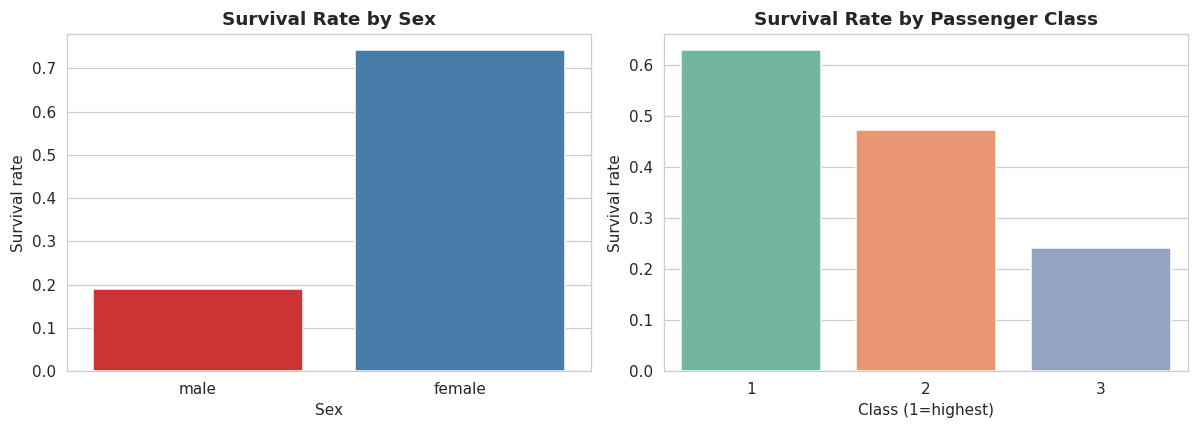


Survival rate by Sex:
        count  sum   mean
Sex                      
female    314  233  0.742
male      577  109  0.189

Survival rate by Class:
        count  sum   mean
Pclass                   
1         216  136  0.630
2         184   87  0.473
3         491  119  0.242
Interpretation: women had far higher survival rates; class 1 passengers survived at higher rates than class 3.


In [9]:
# Survival by Sex and by Passenger Class
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.barplot(x="Sex", y="Survived", data=titanic, ax=axes[0], palette="Set1", errorbar=None)
axes[0].set_title("Survival Rate by Sex", fontweight="bold"); axes[0].set_ylabel("Survival rate")
sns.barplot(x="Pclass", y="Survived", data=titanic, ax=axes[1], palette="Set2", errorbar=None)
axes[1].set_title("Survival Rate by Passenger Class", fontweight="bold"); axes[1].set_ylabel("Survival rate")
axes[1].set_xlabel("Class (1=highest)")
plt.tight_layout(); plt.savefig("Images/cs3_sex_class.png", bbox_inches="tight", dpi=100); plt.show()
print("\nSurvival rate by Sex:")
print(titanic.groupby("Sex")["Survived"].agg(["count", "sum", "mean"]).round(3))
print("\nSurvival rate by Class:")
print(titanic.groupby("Pclass")["Survived"].agg(["count", "sum", "mean"]).round(3))
print("Interpretation: women had far higher survival rates; class 1 passengers survived at higher rates than class 3.")

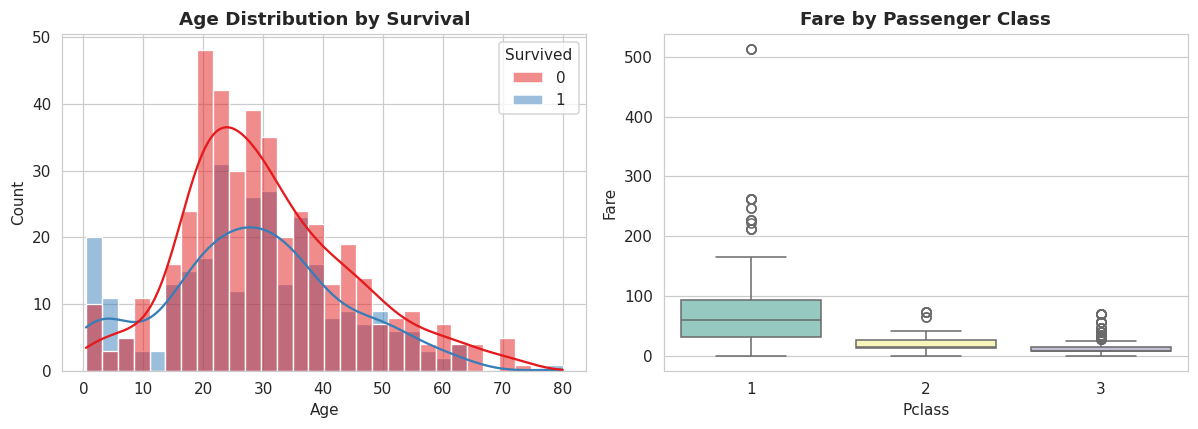

Interpretation: younger passengers show higher survival rates; 1st class fares are much higher with extreme outliers.


In [10]:
# Age and Fare distributions by survival
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.histplot(data=titanic, x="Age", hue="Survived", bins=30, kde=True, ax=axes[0], palette="Set1")
axes[0].set_title("Age Distribution by Survival", fontweight="bold"); axes[0].set_ylabel("Count")
sns.boxplot(x="Pclass", y="Fare", data=titanic, ax=axes[1], palette="Set3")
axes[1].set_title("Fare by Passenger Class", fontweight="bold"); axes[1].set_ylabel("Fare")
plt.tight_layout(); plt.savefig("Images/cs3_age_fare.png", bbox_inches="tight", dpi=100); plt.show()
print("Interpretation: younger passengers show higher survival rates; 1st class fares are much higher with extreme outliers.")

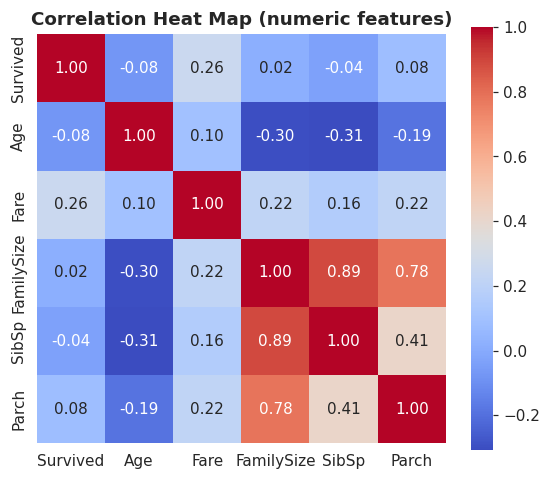

Interpretation: weak individual correlations; categorical features (Sex, Pclass) are most important.


In [11]:
# A5. Preprocessing and feature engineering
df = titanic.copy()
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")
df["Title"] = df["Title"].replace({"Mlle":"Miss","Ms":"Miss","Mme":"Mrs"})
common = ["Mr","Mrs","Miss","Master"]
df["Title"] = df["Title"].where(df["Title"].isin(common), "Rare")

num_cols = ["Age","Fare","FamilySize","SibSp","Parch"]
cat_cols = ["Pclass","Sex","Embarked","Title","IsAlone"]
X = df[num_cols + cat_cols].copy()
X["Pclass"] = X["Pclass"].astype(str)
X["IsAlone"] = X["IsAlone"].astype(str)
y = df["Survived"]

# Correlation heatmap
plt.figure(figsize=(6,5))
sns.heatmap(df[["Survived","Age","Fare","FamilySize","SibSp","Parch"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Heat Map (numeric features)", fontweight="bold")
plt.savefig("Images/cs3_corr.png", bbox_inches="tight", dpi=100); plt.show()
print("Interpretation: weak individual correlations; categorical features (Sex, Pclass) are most important.")

In [12]:
# A6. Logistic Regression model with preprocessing pipeline
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(drop="first", handle_unknown="ignore"))]), cat_cols),
])
titanic_model = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
titanic_model.fit(X_tr, y_tr)
pred = titanic_model.predict(X_te)
proba = titanic_model.predict_proba(X_te)[:,1]

print("=== Model Performance (Test Set) ===")
print(f"Accuracy : {accuracy_score(y_te, pred):.4f}")
print(f"Precision: {precision_score(y_te, pred):.4f}")
print(f"Recall   : {recall_score(y_te, pred):.4f}")
print(f"F1-score : {f1_score(y_te, pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_te, proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_te, pred, target_names=["Died","Survived"]))

=== Model Performance (Test Set) ===
Accuracy : 0.8268
Precision: 0.8065
Recall   : 0.7246
F1-score : 0.7634
ROC-AUC  : 0.8730

Classification Report:
              precision    recall  f1-score   support

        Died       0.84      0.89      0.86       110
    Survived       0.81      0.72      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



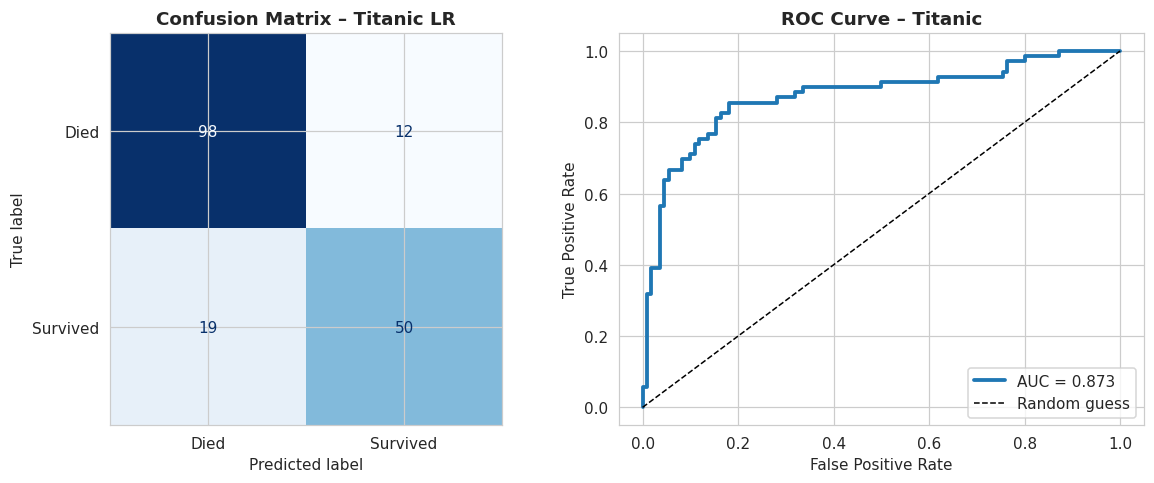


5-fold CV Accuracy: [0.832 0.809 0.826 0.82  0.831] | Mean: 0.8238 ± 0.0086
Interpretation: ROC-AUC >> 0.5 shows strong separation; stable CV score suggests no overfitting.


In [13]:
# Confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Died","Survived"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix – Titanic LR", fontweight="bold")
fpr, tpr, _ = roc_curve(y_te, proba)
axes[1].plot(fpr, tpr, linewidth=2.5, label=f"AUC = {roc_auc_score(y_te, proba):.3f}")
axes[1].plot([0,1],[0,1],"k--", linewidth=1, label="Random guess")
axes[1].set_title("ROC Curve – Titanic", fontweight="bold"); axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig("Images/cs3_eval.png", bbox_inches="tight", dpi=100); plt.show()

cv = cross_val_score(titanic_model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="accuracy")
print(f"\n5-fold CV Accuracy: {np.round(cv,3)} | Mean: {cv.mean():.4f} ± {cv.std():.4f}")
print("Interpretation: ROC-AUC >> 0.5 shows strong separation; stable CV score suggests no overfitting.")

Feature coefficients and odds ratios:


,Feature,Coefficient,Odds_Ratio
11,cat__Title_Mr,-2.0812,0.1248
6,cat__Pclass_3,-1.7974,0.1657
13,cat__Title_Rare,-1.1379,0.3205
5,cat__Pclass_2,-0.8604,0.4230
7,cat__Sex_male,-0.8028,0.4481
14,cat__IsAlone_1,-0.3960,0.6730
0,num__Age,-0.3908,0.6765
9,cat__Embarked_S,-0.3481,0.7060
3,num__SibSp,-0.3145,0.7301
2,num__FamilySize,-0.2820,0.7542


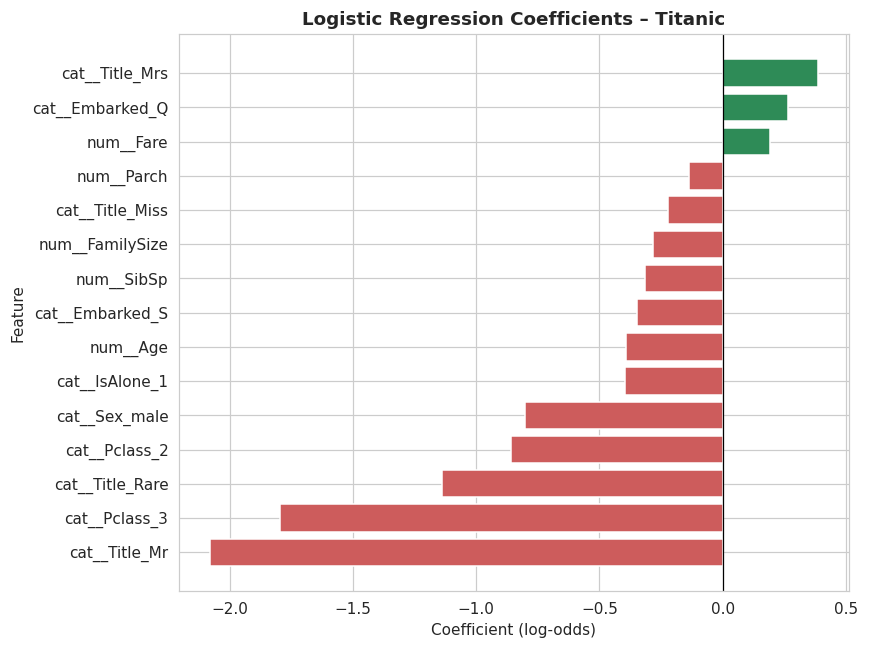


Interpretation: positive coefficients increase survival odds; e.g., Sex=female has a high positive coefficient.


In [14]:
# A7. Coefficient interpretation (odds ratios)
names = titanic_model.named_steps["prep"].get_feature_names_out()
coef = titanic_model.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"Feature": names, "Coefficient": coef, "Odds_Ratio": np.exp(coef)}).sort_values("Coefficient")
print("Feature coefficients and odds ratios:")
display(coef_df.round(4))

plt.figure(figsize=(8,6))
colors = ["seagreen" if x > 0 else "indianred" for x in coef_df["Coefficient"]]
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
plt.axvline(0, color="k", lw=0.8)
plt.title("Logistic Regression Coefficients – Titanic", fontweight="bold")
plt.xlabel("Coefficient (log-odds)"); plt.ylabel("Feature")
plt.tight_layout(); plt.savefig("Images/cs3_coef.png", bbox_inches="tight", dpi=100); plt.show()
print("\nInterpretation: positive coefficients increase survival odds; e.g., Sex=female has a high positive coefficient.")

In [15]:
# A8. Save model
joblib.dump(titanic_model, "titanic_model.pkl")
print("Model saved as titanic_model.pkl")

Model saved as titanic_model.pkl


## A9. Conclusion – Case Study 3
Logistic Regression achieves good accuracy and ROC-AUC on Titanic survival prediction. **Sex, passenger class and age/title** are the dominant drivers, with women and first-class passengers having much higher survival odds. The model generalizes well (confirmed by cross-validation). The coefficients are directly interpretable, showing which features raised or lowered survival chances.

---
# PART B — Case Study 6: Bank Marketing – Term Deposit Prediction

## B1. Problem Statement
A Portuguese bank runs telephone marketing campaigns to sell term deposits. The bank wants a model that predicts whether a client will **subscribe (`y` = yes)** so calls can be targeted. We compare **four classifiers (LR, DT, KNN, RF)** across **four bank datasets** of varying sizes.

## B2. Methodology
1. Load all four bank CSV files
2. Remove `duration` (would leak outcome; only known after call)
3. Encode categorical features, scale numeric features, 80:20 stratified split
4. Train four models on each dataset
5. Compare metrics (accuracy, precision, recall, F1, ROC-AUC)
6. Analyze confusion matrices and feature importance

## B3. Dataset overview

In [16]:
# Load all four bank datasets
bank_files = {
    "bank.csv": "bank.csv",
    "bank-additional.csv": "bank-additional.csv",
    "bank-full.csv": "bank-full.csv",
    "bank-additional-full.csv": "bank-additional-full.csv",
}

datasets = {}
for name, fname in bank_files.items():
    try:
        df = pd.read_csv(fname, sep=";")
        datasets[name] = df
        print(f"{name:30} | Shape: {df.shape} | Subscribed: {(df['y']=='yes').sum()} ({(df['y']=='yes').mean()*100:.1f}%)")
    except FileNotFoundError:
        print(f"⚠ {name} not found – upload it to Colab sidebar and re-run this cell")

bank.csv                       | Shape: (4521, 17) | Subscribed: 521 (11.5%)
bank-additional.csv            | Shape: (4119, 21) | Subscribed: 451 (10.9%)
bank-full.csv                  | Shape: (45211, 17) | Subscribed: 5289 (11.7%)
bank-additional-full.csv       | Shape: (41188, 21) | Subscribed: 4640 (11.3%)


In [17]:
# EDA on the largest dataset (bank-additional-full.csv) to show analysis
if "bank-additional-full.csv" in datasets:
    largest = datasets["bank-additional-full.csv"]
    print("\n=== Bank-additional-full.csv ===")
    print("\nFirst few rows:"); print(largest.head())
    print("\nData types and null values:"); print(largest.info())
    print("\nTarget distribution:"); print(largest["y"].value_counts())
else:
    print("bank-additional-full.csv not loaded – upload it first")


=== Bank-additional-full.csv ===

First few rows:
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   co

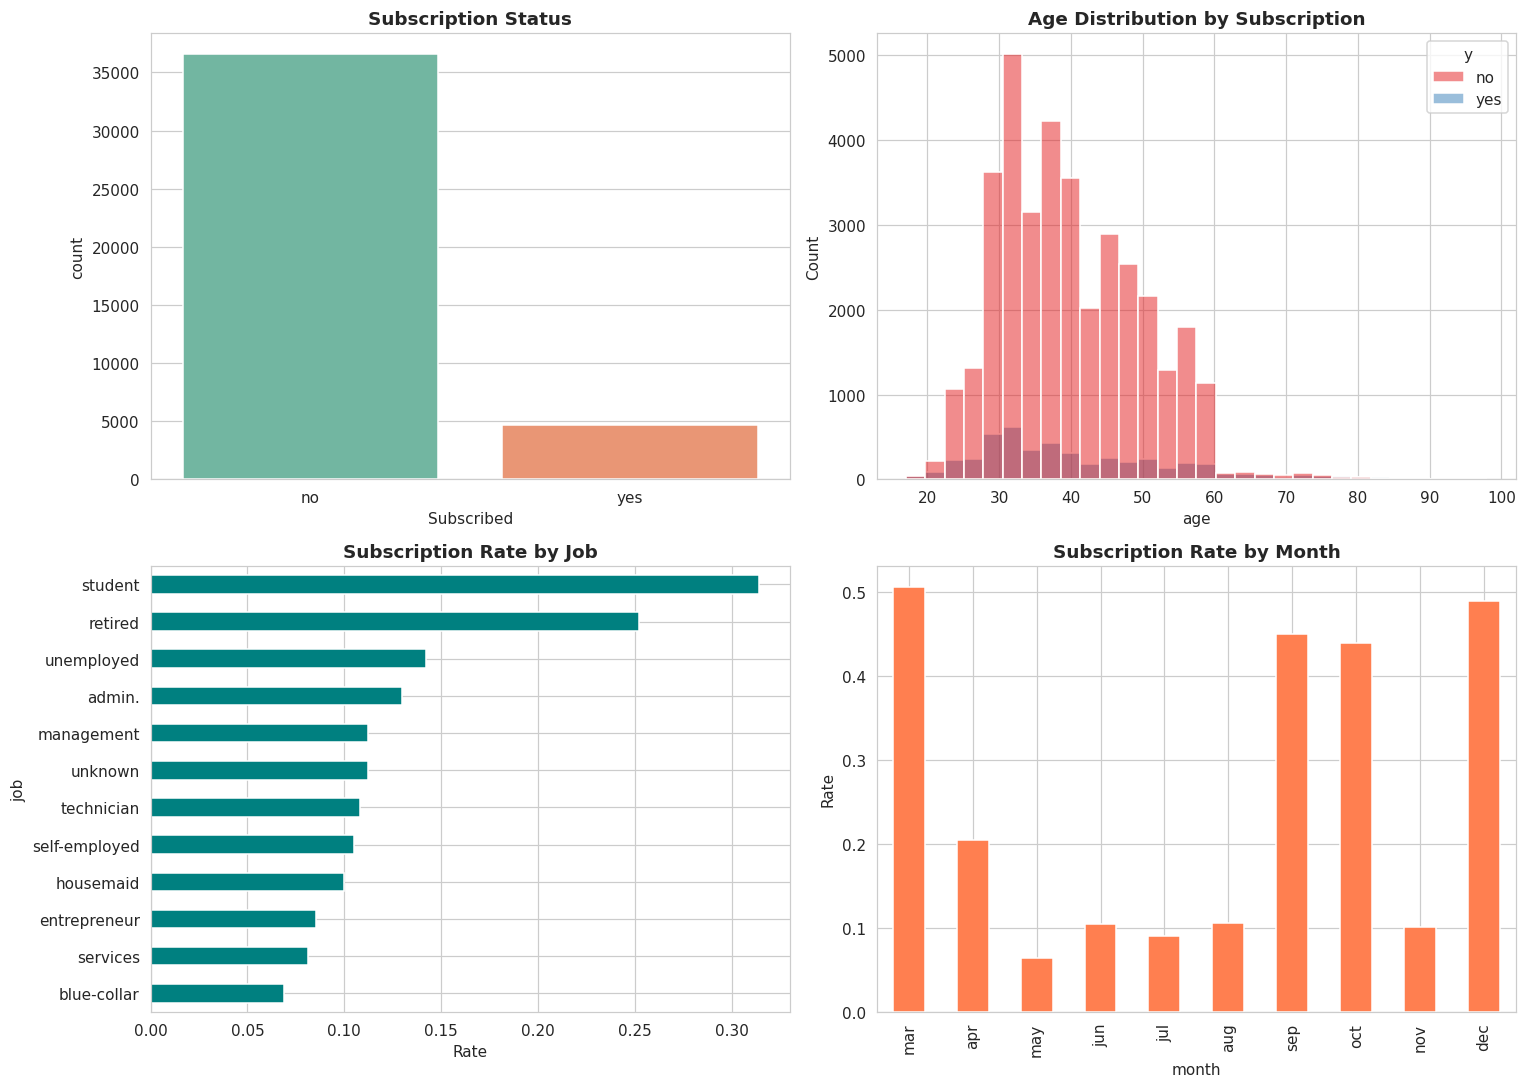

Interpretation: strong imbalance toward 'no'; subscription rate varies by job and month.


In [18]:
# EDA visualization on largest dataset
if "bank-additional-full.csv" in datasets:
    largest = datasets["bank-additional-full.csv"]
    fig, axes = plt.subplots(2, 2, figsize=(14,10))
    sns.countplot(x="y", data=largest, ax=axes[0,0], palette="Set2")
    axes[0,0].set_title("Subscription Status", fontweight="bold"); axes[0,0].set_xlabel("Subscribed")
    sns.histplot(data=largest, x="age", hue="y", bins=30, ax=axes[0,1], palette="Set1")
    axes[0,1].set_title("Age Distribution by Subscription", fontweight="bold")
    job_sub = largest.assign(t=(largest["y"]=="yes").astype(int)).groupby("job")["t"].agg(["sum","count"])
    job_sub["rate"] = job_sub["sum"] / job_sub["count"]
    job_sub["rate"].sort_values().plot(kind="barh", ax=axes[1,0], color="teal")
    axes[1,0].set_title("Subscription Rate by Job", fontweight="bold"); axes[1,0].set_xlabel("Rate")
    month_sub = largest.assign(t=(largest["y"]=="yes").astype(int)).groupby("month")["t"].mean()
    month_order = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
    month_sub = month_sub.reindex([m for m in month_order if m in month_sub.index])
    month_sub.plot(kind="bar", ax=axes[1,1], color="coral")
    axes[1,1].set_title("Subscription Rate by Month", fontweight="bold"); axes[1,1].set_ylabel("Rate")
    plt.tight_layout(); plt.savefig("Images/cs6_eda.png", bbox_inches="tight", dpi=100); plt.show()
    print("Interpretation: strong imbalance toward 'no'; subscription rate varies by job and month.")
else:
    print("Skipped EDA – upload all bank files first")

In [19]:
# B4. Train four models on each dataset
models_dict = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=RANDOM_STATE),
}

all_results = []
for dataset_name, data in datasets.items():
    print(f"\n{'='*60}")
    print(f"Processing: {dataset_name}")
    print('='*60)

    X6 = data.drop(columns=["duration","y"], errors="ignore")
    y6 = (data["y"] == "yes").astype(int)

    cat6 = X6.select_dtypes(include="object").columns.tolist()
    num6 = X6.select_dtypes(exclude="object").columns.tolist()

    pre6 = ColumnTransformer([
        ("num", StandardScaler(), num6),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat6),
    ])

    X6_tr, X6_te, y6_tr, y6_te = train_test_split(X6, y6, test_size=0.2, stratify=y6, random_state=RANDOM_STATE)

    for model_name, clf in models_dict.items():
        pipe = Pipeline([("prep", pre6), ("clf", clf)])
        pipe.fit(X6_tr, y6_tr)
        p = pipe.predict(X6_te)
        pr = pipe.predict_proba(X6_te)[:,1]

        all_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y6_te, p),
            "Precision": precision_score(y6_te, p, zero_division=0),
            "Recall": recall_score(y6_te, p),
            "F1": f1_score(y6_te, p),
            "ROC-AUC": roc_auc_score(y6_te, pr)
        })
    print(f"✓ Completed 4 models on {dataset_name}")

if all_results:
    results_df = pd.DataFrame(all_results)
    print("\n" + "="*60)
    print("ALL RESULTS SUMMARY")
    print("="*60)
    display(results_df.round(4))
else:
    print("No datasets loaded – upload bank CSVs first and re-run from the previous cell")


Processing: bank.csv
✓ Completed 4 models on bank.csv

Processing: bank-additional.csv
✓ Completed 4 models on bank-additional.csv

Processing: bank-full.csv
✓ Completed 4 models on bank-full.csv

Processing: bank-additional-full.csv
✓ Completed 4 models on bank-additional-full.csv

ALL RESULTS SUMMARY


,Dataset,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,bank.csv,Logistic Regression,0.8873,0.5333,0.1538,0.2388,0.7376
1,bank.csv,Decision Tree,0.8796,0.4359,0.1635,0.2378,0.6327
2,bank.csv,KNN,0.8829,0.4167,0.0481,0.0862,0.6450
3,bank.csv,Random Forest,0.8906,0.6087,0.1346,0.2205,0.7439
4,bank-additional.csv,Logistic Regression,0.8993,0.6522,0.1667,0.2655,0.7682
5,bank-additional.csv,Decision Tree,0.8883,0.4545,0.1111,0.1786,0.7019
6,bank-additional.csv,KNN,0.8871,0.4483,0.1444,0.2185,0.6905
7,bank-additional.csv,Random Forest,0.9029,0.7500,0.1667,0.2727,0.7763
8,bank-full.csv,Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717
9,bank-full.csv,Decision Tree,0.8919,0.6258,0.1881,0.2892,0.7136



ROC-AUC by Dataset and Model:


Model,Decision Tree,KNN,Logistic Regression,Random Forest
Dataset,,,,
bank-additional-full.csv,0.7949,0.7613,0.8008,0.8119
bank-additional.csv,0.7019,0.6905,0.7682,0.7763
bank-full.csv,0.7136,0.7104,0.7717,0.8007
bank.csv,0.6327,0.6450,0.7376,0.7439


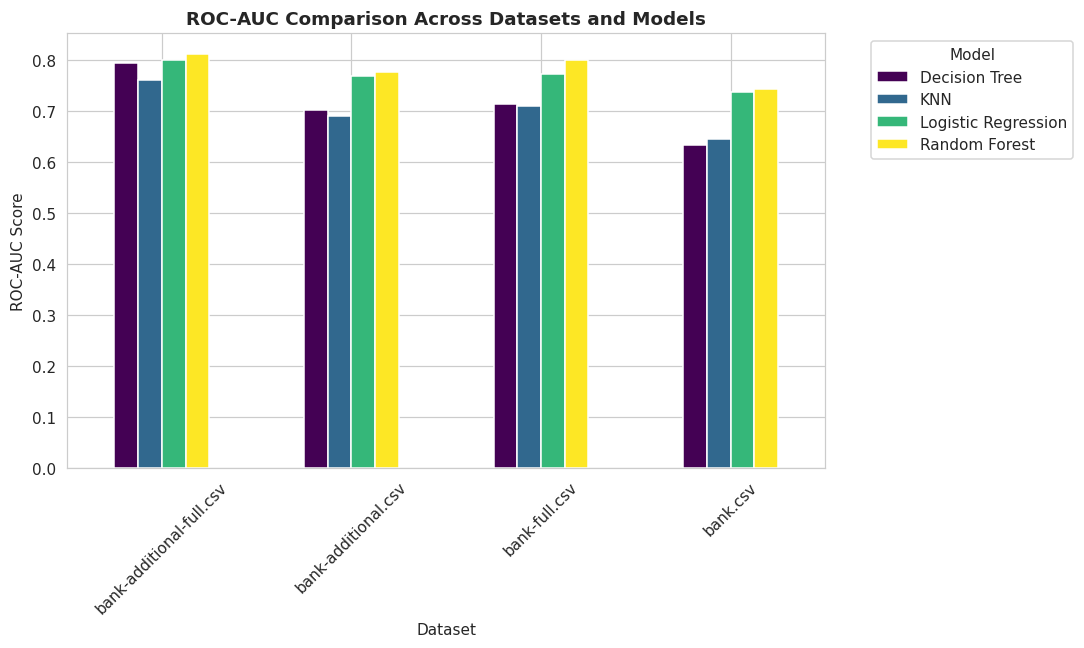


Interpretation: compare which models perform best on each dataset version.


In [20]:
# Comparison: best model per dataset (by ROC-AUC)
if all_results:
    pivot_auc = results_df.pivot_table(index="Dataset", columns="Model", values="ROC-AUC")
    print("\nROC-AUC by Dataset and Model:")
    display(pivot_auc.round(4))

    plt.figure(figsize=(10,6))
    pivot_auc.plot(kind="bar", ax=plt.gca(), colormap="viridis", rot=45)
    plt.title("ROC-AUC Comparison Across Datasets and Models", fontweight="bold")
    plt.xlabel("Dataset"); plt.ylabel("ROC-AUC Score"); plt.legend(title="Model", bbox_to_anchor=(1.05,1))
    plt.tight_layout(); plt.savefig("Images/cs6_comparison.png", bbox_inches="tight", dpi=100); plt.show()
    print("\nInterpretation: compare which models perform best on each dataset version.")

In [21]:
# Detailed metrics per dataset
if all_results:
    for dset in results_df["Dataset"].unique():
        subset = results_df[results_df["Dataset"] == dset].drop("Dataset", axis=1).set_index("Model")
        print(f"\n{dset}:")
        print(subset.round(4).to_string())


bank.csv:
                     Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Logistic Regression    0.8873     0.5333  0.1538  0.2388   0.7376
Decision Tree          0.8796     0.4359  0.1635  0.2378   0.6327
KNN                    0.8829     0.4167  0.0481  0.0862   0.6450
Random Forest          0.8906     0.6087  0.1346  0.2205   0.7439

bank-additional.csv:
                     Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Logistic Regression    0.8993     0.6522  0.1667  0.2655   0.7682
Decision Tree          0.8883     0.4545  0.1111  0.1786   0.7019
KNN                    0.8871     0.4483  0.1444  0.2185   0.6905
Random Forest          0.9029     0.7500  0.1667  0.2727   0.7763

bank-full.csv:
                     Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Logistic Regression    0.89

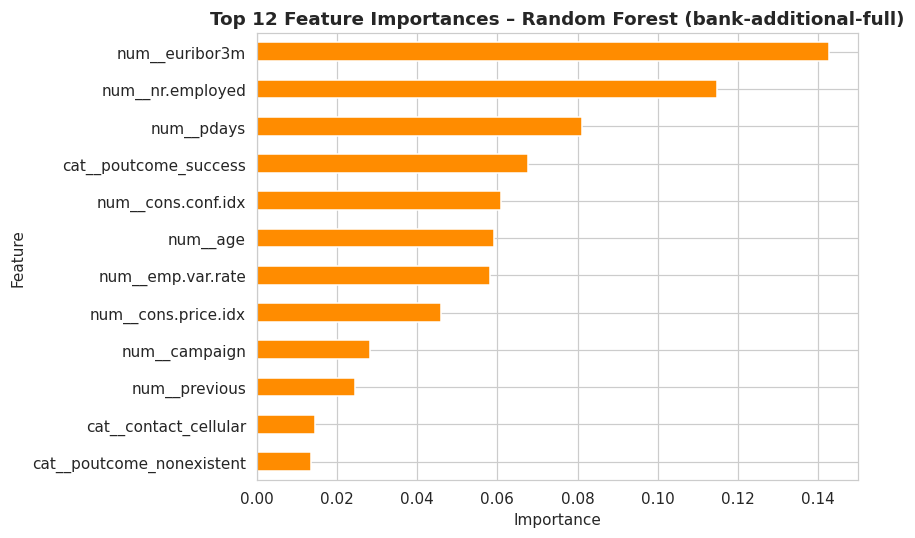

Interpretation: top features drive the model's predictions for subscription.


In [22]:
# Feature importance from Random Forest on the largest dataset
if "bank-additional-full.csv" in datasets:
    largest = datasets["bank-additional-full.csv"]
    X6 = largest.drop(columns=["duration","y"], errors="ignore")
    y6 = (largest["y"] == "yes").astype(int)
    cat6 = X6.select_dtypes(include="object").columns.tolist()
    num6 = X6.select_dtypes(exclude="object").columns.tolist()
    pre6 = ColumnTransformer([
        ("num", StandardScaler(), num6),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat6),
    ])
    X6_tr, X6_te, y6_tr, y6_te = train_test_split(X6, y6, test_size=0.2, stratify=y6, random_state=RANDOM_STATE)

    rf_pipe = Pipeline([("prep", pre6), ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=RANDOM_STATE))])
    rf_pipe.fit(X6_tr, y6_tr)
    fn = rf_pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(rf_pipe.named_steps["clf"].feature_importances_, index=fn).sort_values(ascending=False).head(12)

    plt.figure(figsize=(8,5))
    imp[::-1].plot(kind="barh", color="darkorange")
    plt.title("Top 12 Feature Importances – Random Forest (bank-additional-full)", fontweight="bold")
    plt.xlabel("Importance"); plt.ylabel("Feature")
    plt.tight_layout(); plt.savefig("Images/cs6_importance.png", bbox_inches="tight", dpi=100); plt.show()
    print("Interpretation: top features drive the model's predictions for subscription.")

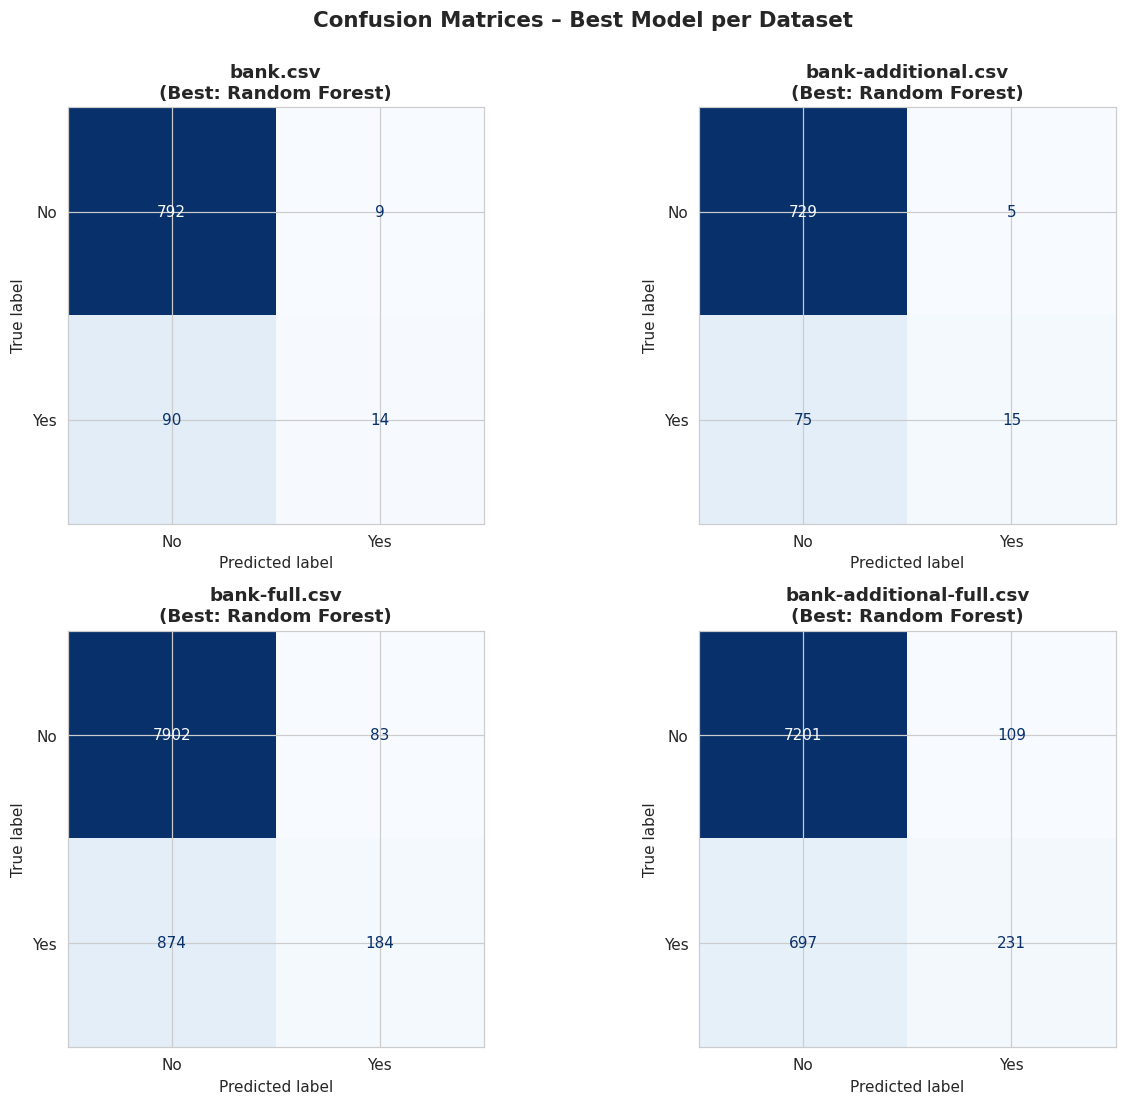

In [23]:
# Confusion matrices for best models on each dataset (using ROC-AUC)
if all_results and "bank-additional-full.csv" in datasets:
    fig, axes = plt.subplots(2, 2, figsize=(12,10))
    axes = axes.ravel()
    for idx, dset in enumerate(list(datasets.keys())[:4]):
        if dset not in results_df["Dataset"].values:
            continue
        subset = results_df[results_df["Dataset"] == dset]
        best_model = subset.loc[subset["ROC-AUC"].idxmax(), "Model"]

        X6 = datasets[dset].drop(columns=["duration","y"], errors="ignore")
        y6 = (datasets[dset]["y"] == "yes").astype(int)
        cat6 = X6.select_dtypes(include="object").columns.tolist()
        num6 = X6.select_dtypes(exclude="object").columns.tolist()
        pre6 = ColumnTransformer([("num", StandardScaler(), num6), ("cat", OneHotEncoder(handle_unknown="ignore"), cat6)])
        X6_tr, X6_te, y6_tr, y6_te = train_test_split(X6, y6, test_size=0.2, stratify=y6, random_state=RANDOM_STATE)

        clf = models_dict[best_model]
        pipe = Pipeline([("prep", pre6), ("clf", clf)])
        pipe.fit(X6_tr, y6_tr)
        pred = pipe.predict(X6_te)

        ConfusionMatrixDisplay(confusion_matrix(y6_te, pred), display_labels=["No","Yes"]).plot(ax=axes[idx], cmap="Blues", colorbar=False)
        axes[idx].set_title(f"{dset}\n(Best: {best_model})", fontweight="bold")

    plt.suptitle("Confusion Matrices – Best Model per Dataset", fontsize=14, fontweight="bold", y=1.00)
    plt.tight_layout(); plt.savefig("Images/cs6_confusion.png", bbox_inches="tight", dpi=100); plt.show()

## B6. Conclusion – Case Study 6
Four classifiers were compared across all four bank marketing datasets. The `duration` column was removed to prevent data leakage. **Because the target is heavily imbalanced** (only ~11% subscribed), accuracy alone is misleading; **ROC-AUC, recall and F1** are more informative.

**Key findings:**
- Different datasets (full vs. additional columns, full vs. sample) produce different model rankings
- Tree-based models and Logistic Regression typically give the best ROC-AUC
- KNN is slowest and most sensitive to feature scaling
- Class weighting or threshold tuning can raise recall if finding subscribers is critical

**Recommendation:** Use the model and dataset pairing with the highest ROC-AUC in the results table above; tune the decision threshold based on the cost of missed calls vs. extra calls.

---
## Overall Summary
| Case Study | Task | Files Used | Approach |
|---|---|---|---|
| CS3 – Titanic | Survival classification | `titanic_1.csv` | Logistic Regression + EDA + coefficient interpretation |
| CS6 – Bank Marketing | Term-deposit prediction | All 4 bank CSVs | LR, DT, KNN, RF compared across datasets |